# Handwritten Digit Recognition: A Reproducible Mini-Project

**Scope:** classification of isolated digits 0-9 using logistic regression and a three-block CNN.

**Data provenance:** this executed experiment uses 2,000 real handwritten images sampled from public MNIST, not handwriting collected by the student. It demonstrates the complete technical pipeline, but does **not** fulfill the assignment's self-collection requirement. `self_collected_template.ipynb` supports a replacement dataset with writer-disjoint splits.

MNIST attribution: Yann LeCun and Corinna Cortes; derived from NIST data. Source and license: https://keras.io/api/datasets/mnist/ (CC BY-SA 3.0). This selected, inverted PNG subset is distributed under the same dataset license. Download location documented by TensorFlow: https://www.tensorflow.org/tutorials/load_data/numpy .

Run from the project folder. Install `requirements.txt` before running. The exported PNG dataset and manifest are included; downloading MNIST again is needed only to rebuild that dataset.

In [1]:
# Dependencies: python -m pip install -r requirements.txt
# In Colab, uncomment the following line:
# %pip install numpy pandas pillow matplotlib scikit-learn torch torchvision joblib

## 1. Setup
Seed 42 is fixed for image selection, augmentation, and model initialization. CPU execution uses up to four threads. Each class contains 140 training images, 30 validation images, and 30 test images. Training and validation are sampled from the official training partition; the test subset comes from the official test partition. No writer IDs are supplied in this archive, so writer-disjoint validation cannot be asserted.

In [2]:
from pathlib import Path
import copy, hashlib, json, random
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, ConfusionMatrixDisplay
import joblib

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
ROOT = Path('data/mnist_subset')
OUT = Path('results'); OUT.mkdir(exist_ok=True)
import os, time
torch.set_num_threads(min(4, os.cpu_count() or 1))
experiment_started = time.perf_counter()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cpu


## 2. Load and audit the frozen dataset
`prepare_data.py` deterministically selects and exports the 2,000-image subset. The manifest records the original MNIST partition and index, split, class, and pixel hash. Exact duplicate images are excluded during selection. This check detects changed files, overlap, label mismatches, and unexpected split sizes. Near-duplicate or stylistically similar handwriting is not eliminated by a pixel hash.

In [3]:
manifest = ROOT/'manifest.csv'
assert manifest.exists(), 'Run python prepare_data.py first, or restore the included dataset.'
df = pd.read_csv(manifest, dtype={'class_name':str})
classes = [str(i) for i in range(10)]
df['path'] = df['relative_path'].map(lambda p: str(ROOT/p))
assert len(df) == 2000 and not df['relative_path'].duplicated().any()
assert not df.duplicated(['source_partition','source_index']).any()
assert set(df['split']) == {'train','val','test'}
hashes = []
for row in df.itertuples():
    assert row.class_name == classes[row.label]
    assert row.source_partition == ('test' if row.split == 'test' else 'train')
    with Image.open(row.path) as im:
        im = im.convert('L')
        assert im.size == (28,28)
        digest = hashlib.sha256(im.tobytes()).hexdigest()
    assert digest == row.sha256, f'Changed image: {row.path}'
    hashes.append(digest)
assert len(set(hashes)) == len(hashes), 'Exact duplicates found.'
counts = pd.crosstab(df.class_name,df.split).reindex(index=classes,columns=['train','val','test'])
assert (counts.to_numpy() == np.array([140,30,30])).all()
display(counts)
df.to_csv(OUT/'dataset_manifest.csv',index=False)
counts.to_csv(OUT/'dataset_counts.csv')
(OUT/'classes.json').write_text(json.dumps(classes),encoding='utf-8')
parts = {s:df[df.split==s].reset_index(drop=True) for s in ['train','val','test']}
print('Audit passed: 2,000 unique images; 1,400 train / 300 validation / 300 test.')

split,train,val,test
class_name,,,
0,140,30,30
1,140,30,30
2,140,30,30
3,140,30,30
4,140,30,30
5,140,30,30
6,140,30,30
7,140,30,30
8,140,30,30


Audit passed: 2,000 unique images; 1,400 train / 300 validation / 300 test.


## 3. Preprocessing and augmentation
Convert to grayscale, invert dark ink to a bright foreground, preserve aspect ratio while fitting into 24×24 pixels, and pad to 32×32. Scale pixels to [0,1]. Training-only augmentation uses small rotations and translations. Avoid horizontal/vertical flips, which can change the character's meaning. Both models receive originals plus one fixed augmented training copy so their comparison uses the same input data.

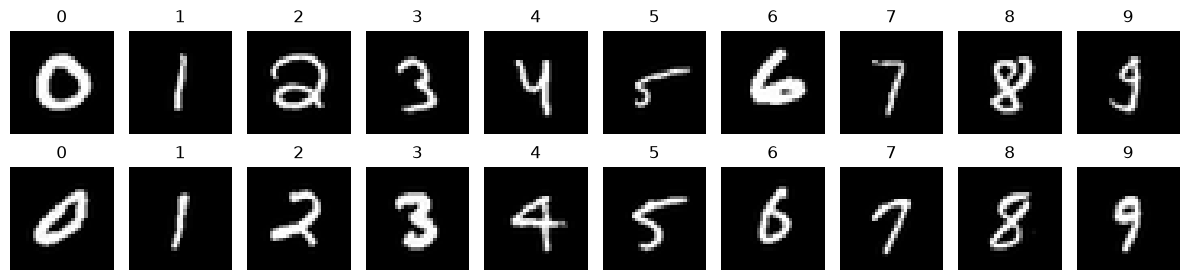

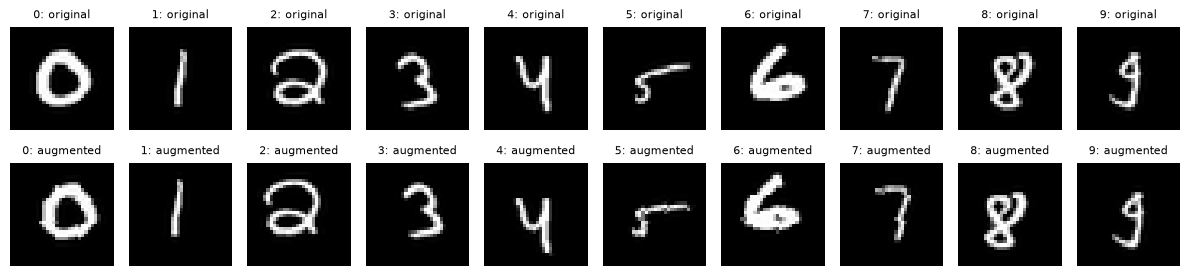

In [4]:
def preprocess(path):
    with Image.open(path) as raw:
        im = ImageOps.invert(ImageOps.exif_transpose(raw).convert('L'))
        im = ImageOps.contain(im, (24,24), method=Image.Resampling.LANCZOS)
        canvas = Image.new('L', (32,32), 0)
        canvas.paste(im, ((32-im.width)//2, (32-im.height)//2))
        return canvas

augment = transforms.RandomAffine(degrees=10, translate=(0.08,0.08), fill=0)
to_tensor = transforms.ToTensor()
def tensors(frame, augmented=False):
    images = [preprocess(p) for p in frame.path]
    X = torch.stack([to_tensor(im) for im in images])
    y = torch.tensor(frame.label.to_numpy(), dtype=torch.long)
    if augmented:
        X = torch.cat([X, torch.stack([to_tensor(augment(im)) for im in images])])
        y = torch.cat([y,y])
    return X,y

Xtrain,ytrain = tensors(parts['train'], augmented=True)
Xval,yval = tensors(parts['val'])
# Test pixels are loaded only in the final evaluation section.
fig, axes = plt.subplots(2,10,figsize=(12,3))
example_ids = [int(parts['train'].index[parts['train'].label==c][j]) for j in range(2) for c in range(10)]
for ax,i in zip(axes.flat, example_ids):
    ax.imshow(Xtrain[i,0],cmap='gray'); ax.set_title(classes[ytrain[i].item()]); ax.axis('off')
plt.tight_layout(); plt.savefig(OUT/'training_examples.png', dpi=180); plt.show()
fig,axes = plt.subplots(2,10,figsize=(12,3))
for c in range(10):
    i = int(parts['train'].index[parts['train'].label==c][0])
    for r,offset in enumerate([0,len(parts['train'])]):
        axes[r,c].imshow(Xtrain[i+offset,0],cmap='gray')
        axes[r,c].axis('off'); axes[r,c].set_title(f'{c}: '+('original' if r==0 else 'augmented'),fontsize=8)
plt.tight_layout(); plt.savefig(OUT/'augmentation_examples.png',dpi=180); plt.show()

## 4. Baseline: logistic regression
Flatten images into 1,024 features. Select regularization using validation macro F1 only. Macro F1 weights each class equally.

In [5]:
baseline_started = time.perf_counter()
baseline, best_score, baseline_trials = None, -1, []
for C in [0.1, 1.0, 10.0]:
    model = LogisticRegression(C=C, max_iter=2000, random_state=SEED)
    model.fit(Xtrain.flatten(1).numpy(), ytrain.numpy())
    pred = model.predict(Xval.flatten(1).numpy())
    score = precision_recall_fscore_support(yval.numpy(),pred,average='macro',zero_division=0)[2]
    baseline_trials.append({'C': C, 'validation_macro_f1': score})
    if score > best_score: baseline, best_score = model, score
display(pd.DataFrame(baseline_trials))
pd.DataFrame(baseline_trials).to_csv(OUT/'baseline_validation.csv',index=False)
joblib.dump(baseline, OUT/'logistic_regression.joblib')
baseline_seconds = time.perf_counter()-baseline_started
print('Selected C:', baseline.C, '| seconds:', round(baseline_seconds,2))

,C,validation_macro_f1
0,0.1,0.878405
1,1.0,0.858238
2,10.0,0.813008


Selected C: 0.1 | seconds: 3.22


## 5. Improved model: convolutional neural network
Three convolution blocks learn spatial stroke patterns. Dropout and validation-based early stopping limit overfitting. The term “improved model” describes the proposed architecture, not a guaranteed improvement in measured accuracy.

{'epoch': 1, 'train_loss': 2.093029428209577, 'val_loss': 1.1842482089996338, 'val_macro_f1': 0.6240542203277952}


{'epoch': 2, 'train_loss': 1.0167919349670411, 'val_loss': 0.3985455334186554, 'val_macro_f1': 0.891780358559469}


{'epoch': 3, 'train_loss': 0.5886508630003248, 'val_loss': 0.24177676439285278, 'val_macro_f1': 0.9401669391864695}


{'epoch': 4, 'train_loss': 0.44746209161622186, 'val_loss': 0.19765959680080414, 'val_macro_f1': 0.9497503552108583}


{'epoch': 5, 'train_loss': 0.3530245053768158, 'val_loss': 0.19935433566570282, 'val_macro_f1': 0.9400467869653519}


{'epoch': 6, 'train_loss': 0.29829197781426564, 'val_loss': 0.16230350732803345, 'val_macro_f1': 0.9568143632308008}


... (16 outputs left out)

{'epoch': 23, 'train_loss': 0.07101371425603117, 'val_loss': 0.12656667828559875, 'val_macro_f1': 0.9664824396592676}


{'epoch': 24, 'train_loss': 0.053934018835425375, 'val_loss': 0.11054942011833191, 'val_macro_f1': 0.9633652569975878}


{'epoch': 25, 'train_loss': 0.047929417310016494, 'val_loss': 0.12349202483892441, 'val_macro_f1': 0.9698641886931737}


{'epoch': 26, 'train_loss': 0.06212670522076743, 'val_loss': 0.12010610103607178, 'val_macro_f1': 0.9664673857565511}


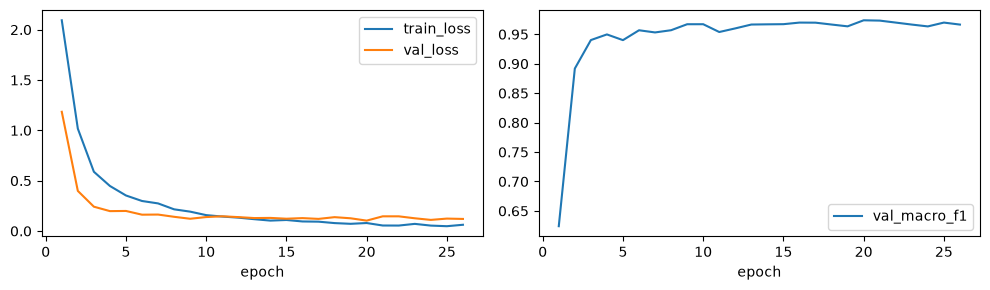

CNN parameters: 356234 | seconds: 56.29


In [6]:
cnn_started = time.perf_counter()
cnn = nn.Sequential(
    nn.Conv2d(1,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(128*4*4,128), nn.ReLU(), nn.Dropout(0.4),
    nn.Linear(128,len(classes))
).to(DEVICE)
loader = DataLoader(torch.utils.data.TensorDataset(Xtrain,ytrain),batch_size=64,shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001, weight_decay=0.0001)
loss_fn = nn.CrossEntropyLoss()
def predict_cnn(X):
    cnn.eval()
    with torch.no_grad():
        return torch.cat([cnn(batch.to(DEVICE)).argmax(1).cpu() for batch in X.split(128)]).numpy()

history, best_state, best_f1, stale = [], None, -1, 0
for epoch in range(1,31):
    cnn.train(); total_loss = 0
    for xb,yb in loader:
        xb,yb = xb.to(DEVICE),yb.to(DEVICE)
        optimizer.zero_grad(); loss = loss_fn(cnn(xb),yb)
        loss.backward(); optimizer.step(); total_loss += loss.item()*len(xb)
    val_pred = predict_cnn(Xval)
    f1 = precision_recall_fscore_support(yval.numpy(),val_pred,average='macro',zero_division=0)[2]
    with torch.no_grad():
        val_loss = loss_fn(cnn(Xval.to(DEVICE)),yval.to(DEVICE)).item()
    history.append({'epoch':epoch,'train_loss':total_loss/len(Xtrain),'val_loss':val_loss,'val_macro_f1':f1})
    print(history[-1])
    if f1 > best_f1:
        best_f1, best_state, stale = f1, copy.deepcopy(cnn.state_dict()), 0
    else: stale += 1
    if stale >= 6: break
cnn.load_state_dict(best_state)
torch.save({'state_dict':cnn.cpu().state_dict(),'classes':classes}, OUT/'cnn.pt')
cnn.to(DEVICE)
hist = pd.DataFrame(history); hist.to_csv(OUT/'training_history.csv',index=False)
fig,axes = plt.subplots(1,2,figsize=(10,3))
hist.plot(x='epoch',y=['train_loss','val_loss'],ax=axes[0]); hist.plot(x='epoch',y='val_macro_f1',ax=axes[1])
plt.tight_layout(); plt.savefig(OUT/'learning_curves.png',dpi=180); plt.show()
cnn_seconds = time.perf_counter()-cnn_started
print('CNN parameters:', sum(p.numel() for p in cnn.parameters()), '| seconds:', round(cnn_seconds,2))

## 6. Final held-out evaluation
Run after all model choices are fixed. Report accuracy, macro precision, macro recall, macro F1, per-class scores, and confusion matrices. Do not tune models using these test results.

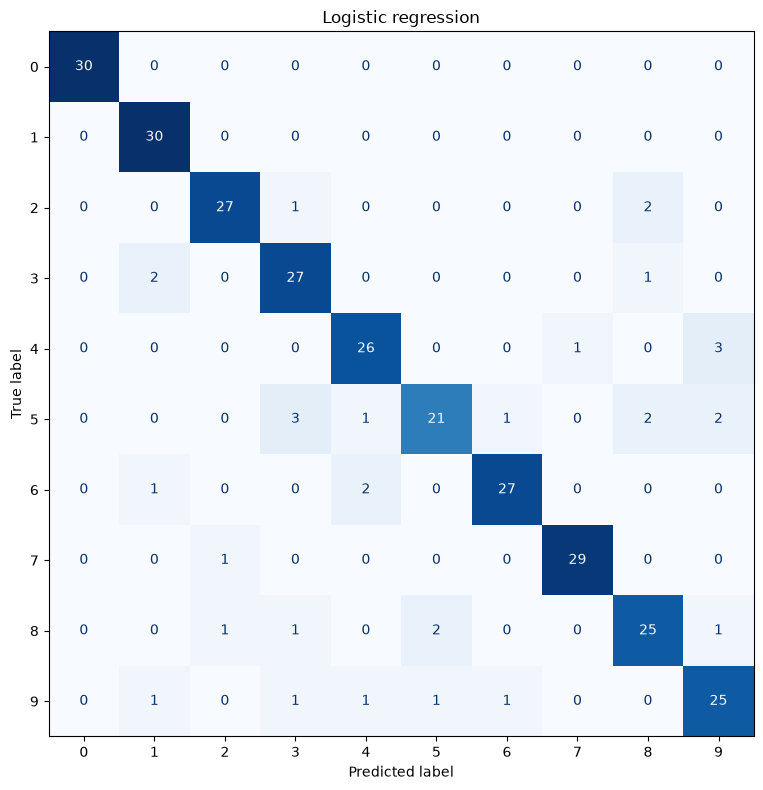

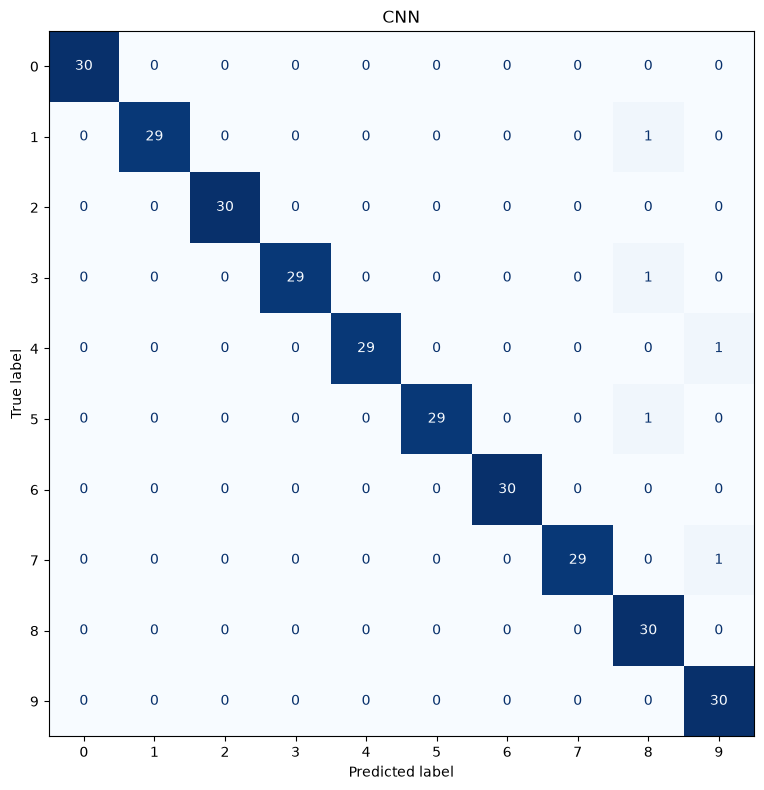

,model,accuracy,precision_macro,recall_macro,f1_macro
0,Logistic regression,0.890000,0.891072,0.890000,0.888927
1,CNN,0.983333,0.984659,0.983333,0.983538


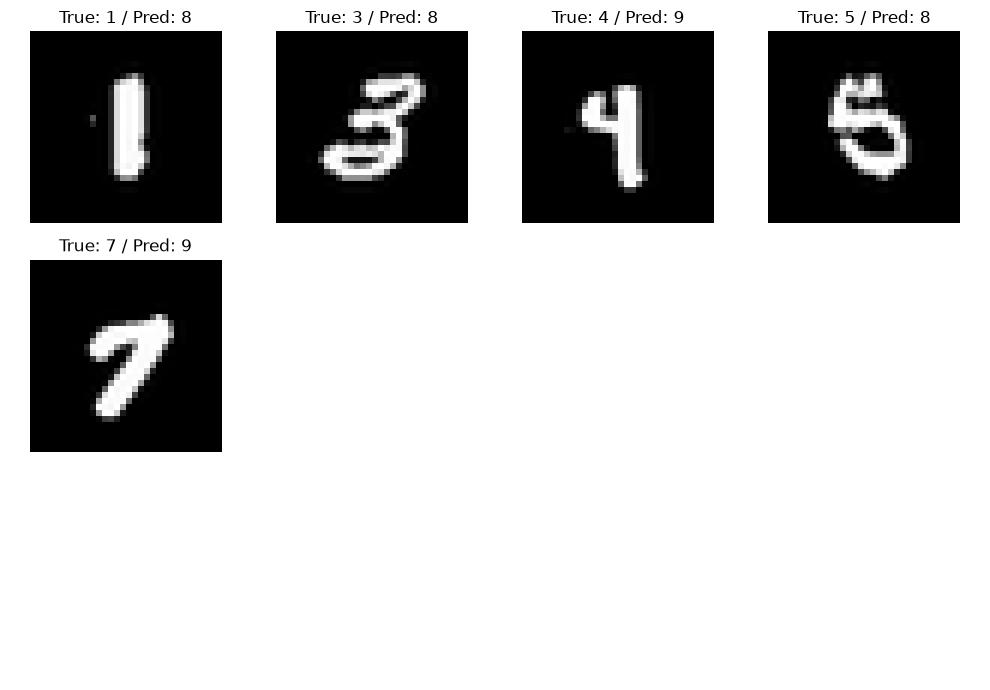

Image-level bootstrap accuracy intervals: {'Logistic regression': [0.8533333333333334, 0.9233333333333333], 'CNN': [0.9666666666666667, 0.9966666666666667], 'CNN_minus_baseline': [0.056666666666666664, 0.13]}


In [7]:
Xtest,ytest = tensors(parts['test'])
predictions = {'Logistic regression':baseline.predict(Xtest.flatten(1).numpy()), 'CNN':predict_cnn(Xtest)}
summary = []
for name,pred in predictions.items():
    precision,recall,f1,_ = precision_recall_fscore_support(ytest.numpy(),pred,average='macro',zero_division=0)
    summary.append(dict(model=name,accuracy=accuracy_score(ytest.numpy(),pred),precision_macro=precision,recall_macro=recall,f1_macro=f1))
    report = classification_report(ytest.numpy(),pred,labels=list(range(len(classes))),target_names=classes,zero_division=0,output_dict=True)
    slug = name.lower().replace(' ','_')
    pd.DataFrame(report).T.to_csv(OUT/f'{slug}_classification_report.csv')
    fig,ax = plt.subplots(figsize=(9,8))
    ConfusionMatrixDisplay.from_predictions(ytest.numpy(),pred,labels=list(range(len(classes))),display_labels=classes,ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(name); plt.tight_layout(); plt.savefig(OUT/f'{slug}_confusion_matrix.png',dpi=180); plt.show()
    table = parts['test'].copy(); table['predicted_class'] = [classes[int(i)] for i in pred]
    table.to_csv(OUT/f'{slug}_predictions.csv',index=False)
summary = pd.DataFrame(summary); display(summary)
summary.to_csv(OUT/'model_comparison.csv',index=False)
wrong = np.flatnonzero(predictions['CNN'] != ytest.numpy())[:12]
if len(wrong):
    fig,axes = plt.subplots(3,4,figsize=(10,7))
    for ax in axes.flat: ax.axis('off')
    for ax,i in zip(axes.flat,wrong):
        ax.imshow(Xtest[i,0],cmap='gray')
        ax.set_title(f'True: {classes[ytest[i].item()]} / Pred: {classes[int(predictions["CNN"][i])]}')
    plt.tight_layout(); plt.savefig(OUT/'cnn_errors.png',dpi=180); plt.show()
else: print('No CNN misclassifications in this test split.')
# Paired bootstrap: same resampled test images for both models, seed fixed.
# Describes this small image-level test sample, not writer-level uncertainty.
rng = np.random.default_rng(SEED)
truth = ytest.numpy()
boot = rng.integers(0,len(truth),size=(5000,len(truth)))
correct = {name:(p==truth).astype(float) for name,p in predictions.items()}
intervals = {name:np.quantile(v[boot].mean(axis=1),[0.025,0.975]).tolist() for name,v in correct.items()}
delta = correct['CNN']-correct['Logistic regression']
intervals['CNN_minus_baseline'] = np.quantile(delta[boot].mean(axis=1),[0.025,0.975]).tolist()
(OUT/'accuracy_bootstrap.json').write_text(json.dumps(intervals,indent=2),encoding='utf-8')
print('Image-level bootstrap accuracy intervals:',intervals)

## 7. Measured conclusion and limitations
The next cell generates a conclusion directly from the saved measurements. See `output/pdf/assignment_report.pdf` for the four-page report and `REPORT.md` for editable text.

This experiment does not test mathematical symbols, full equations, phone photographs, or unseen-writer validation. It uses public MNIST images, not a self-collected dataset. Evaluation uses one seed and a small balanced test subset. Both models use exactly the same original and augmented training examples. Repeated trials and fresh handwriting are appropriate follow-up work.

In [8]:
import sys, importlib.metadata
versions = {name: importlib.metadata.version(name) for name in ['numpy','pandas','Pillow','matplotlib','scikit-learn','torch','torchvision']}
versions.update(python=sys.version,device=str(DEVICE),seed=SEED)
(OUT/'environment.json').write_text(json.dumps(versions,indent=2),encoding='utf-8')
print('Saved experiment artifacts to', OUT.resolve())
run = dict(seed=SEED,dataset='MNIST subset (not self-collected)',train_original=1400,train_with_augmentation=2800,validation=300,test=300,
           baseline_C=baseline.C,baseline_seconds=baseline_seconds,cnn_seconds=cnn_seconds,
           cnn_parameters=sum(p.numel() for p in cnn.parameters()),epochs_run=len(hist),
           best_epoch=int(hist.loc[hist.val_macro_f1.idxmax(),'epoch']),
           best_validation_macro_f1=float(hist.val_macro_f1.max()),
           total_seconds=time.perf_counter()-experiment_started)
(OUT/'run_summary.json').write_text(json.dumps(run,indent=2),encoding='utf-8')
a = summary.set_index('model')
gap = 100*(a.loc['CNN','accuracy']-a.loc['Logistic regression','accuracy'])
print(f"Test accuracy: logistic regression {a.loc['Logistic regression','accuracy']:.2%}; CNN {a.loc['CNN','accuracy']:.2%}.")
print(f'CNN accuracy difference: {gap:+.2f} percentage points. Test size: 300 images.')
print('Remaining assignment requirement: collect original handwriting and repeat the experiment.')

Saved experiment artifacts to C:\Users\mansu\Desktop\assik1comp\results
Test accuracy: logistic regression 89.00%; CNN 98.33%.
CNN accuracy difference: +9.33 percentage points. Test size: 300 images.
Remaining assignment requirement: collect original handwriting and repeat the experiment.
